#  1% Noise

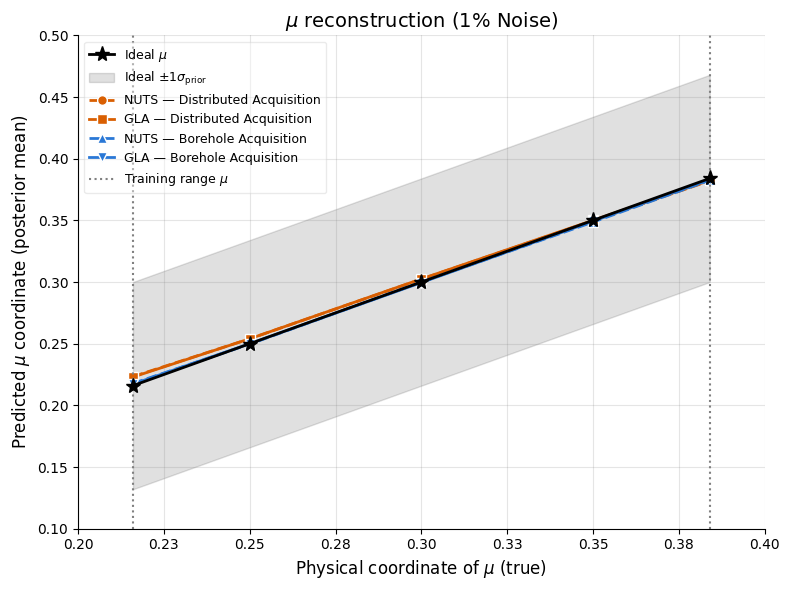

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# ── Data ────────────────────────────────────────────────────────────────────
Physical_coordinates_mu = np.array([0.216, 0.25, 0.3, 0.35, 0.384])   # x-axis (swept)


# (500 + 500) samples
data = {
    "mu": {
        "true": None,
        "det_U": np.array([0.22295986, 0.25398248, 0.30249795, 0.35003419,  0.38243917]),
        "nuts_U": np.array([0.22334015, 0.25399877, 0.30237307, 0.34975498, 0.38200945]),
        "det_N": np.array([0.2172819, 0.24999952 , 0.29955761, 0.34928491, 0.38294929]),
        "nuts_N": np.array([0.21782584, 0.24965088,0.29996491, 0.34861267, 0.38250472]),
    },
    
}

# ── Training domain ─────────────────────────────────────────────────────────
mu_train_lo = 0.216
mu_train_hi = 0.384



# ── Style ───────────────────────────────────────────────────────────────────
color_nonuniform = "#2a78d6"
color_uniform = "#d95f02"

lw = 2.0
ms = 7

sigma_prior = 0.084


# ── Figure ──────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 6))


# ── Ideal μ4 identity line ──────────────────────────────────────────────────
ax.plot(
    Physical_coordinates_mu,
    Physical_coordinates_mu,
    color="black",
    lw=lw,
    ls="-",
    marker="*",
    markersize=ms+4,
    label=r"Ideal $\mu$",
    zorder=5
)


# ── Prior uncertainty band ──────────────────────────────────────────────────
ax.fill_between(
    Physical_coordinates_mu,
    Physical_coordinates_mu - sigma_prior,
    Physical_coordinates_mu + sigma_prior,
    color="black",
    alpha=0.12,
    label=r"Ideal $\pm1\sigma_{\rm prior}$"
)


# ── Uniform NUTS ────────────────────────────────────────────────────────────
ax.plot(
    Physical_coordinates_mu,
    data["mu"]["nuts_U"],
    color=color_uniform,
    lw=lw,
    ls="--",
    marker="o",
    markersize=ms,
    markerfacecolor=color_uniform,
    markeredgecolor="white",
    markeredgewidth=1,
    label="NUTS — Distributed Acquisition"
)


# ── Uniform Deterministic ───────────────────────────────────────────────────
ax.plot(
    Physical_coordinates_mu,
    data["mu"]["det_U"],
    color=color_uniform,
    lw=lw,
    ls="-",
    marker="s",
    markersize=ms,
    markerfacecolor=color_uniform,
    markeredgecolor="white",
    markeredgewidth=1,
    label="GLA — Distributed Acquisition"
)


# ── Non-uniform NUTS ─────────────────────────────────────────────────────────
ax.plot(
    Physical_coordinates_mu,
    data["mu"]["nuts_N"],
    color=color_nonuniform,
    lw=lw,
    ls="--",
    marker="^",
    markersize=ms,
    markerfacecolor=color_nonuniform,
    markeredgecolor="white",
    markeredgewidth=1,
    label="NUTS — Borehole Acquisition"
)


# ── Non-uniform Deterministic ────────────────────────────────────────────────
ax.plot(
    Physical_coordinates_mu,
    data["mu"]["det_N"],
    color=color_nonuniform,
    lw=lw,
    ls="-",
    marker="v",
    markersize=ms,
    markerfacecolor=color_nonuniform,
    markeredgecolor="white",
    markeredgewidth=1,
    label="GLA — Borehole Acquisition"
)


# ── Training range μ4 ───────────────────────────────────────────────────────
ax.axvline(
    mu_train_lo,
    color="gray",
    lw=1.5,
    ls=":",
    label=r"Training range $\mu$"
)

ax.axvline(
    mu_train_hi,
    color="gray",
    lw=1.5,
    ls=":"
)


# ── Formatting ──────────────────────────────────────────────────────────────
ax.set_xlabel(
    r"Physical coordinate of $\mu$ (true)",
    fontsize=12
)

ax.set_ylabel(
    r"Predicted $\mu$ coordinate (posterior mean)",
    fontsize=12
)

ax.set_title(
    r"$\mu$ reconstruction (1% Noise)",
    fontsize=14
)


ax.set_xlim(0.2,0.4)
ax.set_ylim(0.1,0.5)


ax.xaxis.set_major_formatter(
    ticker.FormatStrFormatter("%.2f")
)

ax.yaxis.set_major_formatter(
    ticker.FormatStrFormatter("%.2f")
)


ax.tick_params(labelsize=10)

ax.grid(
    color="gray",
    alpha=0.2,
    linewidth=0.8
)

ax.spines[["top","right"]].set_visible(False)


ax.legend(
    fontsize=9,
    framealpha=0.4,
    loc="best"
)


plt.tight_layout()


plt.savefig(
    "SD2LSP_inversion_1.pdf",
    bbox_inches="tight",
    dpi=150
)

plt.savefig(
    "SD2LSP_inversion_1.png",
    bbox_inches="tight",
    dpi=150
)


plt.show()

In [5]:
Relative_function_U = np.array([0.9979, 0.9979, 0.9979, 0.9979, 0.9979])
Relative_function_N = np.array([0.9995, 0.9994, 0.9994, 0.9995, 0.9995])

Relative_Jacobian_U = np.array([0.9065, 0.9855, 0.9759, 0.9867, 0.9855])
Relative_Jacobian_N = np.array([0.9280, 0.9979, 0.9826, 0.9939, 0.9916])

# Uniform
# shift = np.array([0.03]) # 0.384 

(gempy_dino) deepprakashravi@MacBookPro unifrom % python inversion2.py
Setting Backend To: AvailableBackends.numpy
Script started...
Using MPS device
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Active grids: ['custom']
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Using MPS device
[[-0.14285714  0.          0.        ]
 [ 0.          0.          0.        ]
 [ 0.14285714  0.          0.        ]]
Setting Backend To: AvailableBackends.PYTORCH
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/generate_samples2.py:159: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Inputs_samples = torch.tensor(Inputs_samples, dtype=self.dtype, device=self.device)
Condition number: 1277.4216981219856.
0.0
B_pseudo_inverse.shape: (3969, 400)
M_U.shape: (3969, 3969)
M_obs.shape: (400, 400)
u_uT.shape: (400, 400)
u_M_norm.shape: 0.03347716316302197
trace of M_obs: 0.13051056908556816
||del u||: 0.018331392090257588


Deterministic inversion


Sampling_type: unifrom
Model name: SD2LSP
Using MPS device
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/gradient.py:67: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  interpolation_matrix = torch.tensor(interpolation_matrix, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/gradient.py:69: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Decoder_matrix = torch.tensor(Decoder_matrix, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/gradient.py:70: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  bias = torch.tensor(bias, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/gradient.py:73: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Sigma_p = torch.tensor(Sigma_p, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/gradient.py:74: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  mean_p = torch.tensor(mean_p, dtype=dtype, device=device)
Train size: 8192,Valid size: 2730,  Test size: 2732
Gradient accuracy: tensor(0.8454, device='mps:0', grad_fn=<RsubBackward1>)
############################################################################
 Data generation range for the model parameters
############################################################################


/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion2.py:410: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0, dtype=torch.float64)), slope=200, filename='posterior_model.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1   0.    0.3  ]
 [0.5   0.    0.384]
 [0.9   0.    0.3  ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion2.py:411: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0 + torch.sqrt(torch.diagonal(Sigma_p)), dtype=torch.float64)), slope=200, filename='posterior_model_plus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1   0.    0.3  ]
 [0.5   0.    0.468]
 [0.9   0.    0.3  ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion2.py:412: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0 - torch.sqrt(torch.diagonal(Sigma_p)), dtype=torch.float64)), slope=200, filename='posterior_model_minus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1 0.  0.3]
 [0.5 0.  0.3]
 [0.9 0.  0.3]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
output mean magnitude tensor(10.4386)
 magnitude  tensor(10.3220)
Jacobian infromation 

Relative Function  between true and surrogate using all the node 
 tensor(0.9977)
Relative Function accuracy between true and surrogate using obs 
 tensor(0.9979)
Function error between true and surrogate using obs 
 tensor(0.0216)
Relative Jacobian accuracy between true and surrogate using all the node 
 tensor(0.9851)
Relative Jacobian accuracy between true and surrogate using all the obs
 tensor(0.9855)
U shape: torch.Size([400, 400])
S: tensor([6.7119])
S_true tensor([6.6435])
Vh shape: torch.Size([1, 1])

 Posterior Covariance
tensor([[2.2143e-06]])
Eigen values of Covariance of posterior
tensor([2.2143e-06+0.j])
Prior mean:
tensor([0.0300], requires_grad=True)
Prior std:
tensor([0.0300])
Posterior mean:
tensor([0.0294], grad_fn=<AddBackward0>)
Posterior std:
tensor([0.0015])
############################################################################
 Data generation range for the model parameters using Gaussian approximation
############################################################################


/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion2.py:493: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post, dtype=torch.float64)), slope=200, filename='posterior_model.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.38243917]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion2.py:494: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post + std_post, dtype=torch.float64)), slope=200, filename='posterior_model_plus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.38660573]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion2.py:495: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post - std_post, dtype=torch.float64)), slope=200, filename='posterior_model_minus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.37827262]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
Warmup [1]:   0%|                                                                                                                                                                           | 0/1000 [00:00, ?it/sSetting Backend To: AvailableBackends.numpy                                                                                                                                                  | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy
Sample [1]: 100%|████████████████████████████████████| 1000/1000 [00:18, 53.79it/s, step size=2.98e-01, acc. prob=0.920]                                                                                           
Sample [2]: 100%|████████████████████████████████████| 1000/1000 [00:18, 53.79it/s, step size=3.14e-01, acc. prob=0.911]                                                                                           
Sample [3]: 100%|████████████████████████████████████| 1000/1000 [00:18, 53.79it/s, step size=5.05e-01, acc. prob=0.622]                                                                                           
Sample [4]: 100%|████████████████████████████████████| 1000/1000 [00:18, 53.79it/s, step size=4.04e-01, acc. prob=0.785]                                                                                           
Sample [5]: 100%|████████████████████████████████████| 1000/1000 [00:18, 53.79it/s, step size=3.18e-01, acc. prob=0.915]                                                                                           





[0]PETSC ERROR: [0]PETSC ERROR: [0]PETSC ERROR: [0]PETSC ERROR: ------------------------------------------------------------------------
------------------------------------------------------------------------
[0]PETSC ERROR: ------------------------------------------------------------------------
------------------------------------------------------------------------
Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
[0]PETSC ERROR: [0]PETSC ERROR: [0]PETSC ERROR: Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
Try option -start_in_debugger or -on_error_attach_debugger
[0]PETSC ERROR: [0]PETSC ERROR: [0]PETSC ERROR: Try option -start_in_debugger or -on_error_attach_debugger
Try option -start_in_debugger or -on_error_attach_debugger
[0]PETSC ERROR: or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
[0]PETSC ERROR: [0]PETSC ERROR: configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
[0]PETSC ERROR: Try option -start_in_debugger or -on_error_attach_debugger
[0]PETSC ERROR: to get more information on the crash.
[0]PETSC ERROR: or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
[0]PETSC ERROR: [0]PETSC ERROR: [0]PETSC ERROR: configure using --with-debugging=yes, recompile, link, and run 
configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: to get more information on the crash.
to get more information on the crash.
[0]PETSC ERROR: to get more information on the crash.
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
MCMC summary results

                mean       std    median      5.0%     95.0%     n_eff     r_hat
      mu_1      0.03      0.00      0.03      0.03      0.03   1156.44      1.01

Number of divergences: 0

Prior mean:  tensor(0.0300) Prior std:  tensor(0.0300)
Posterior mean:  tensor(0.0293) Posterior std:  tensor(0.0015)
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/arviz/data/io_pyro.py:158: UserWarning: Could not get vectorized trace, log_likelihood group will be omitted. Check your model vectorization or set log_likelihood=False
  warnings.warn(
############################################################################
 Data generation range for the model parameters using Pyro posterior samples
############################################################################


Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.38200945]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.38611281]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.37790609]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
Script ended...
Elapsed time: 0:01:09.034268

,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0293),tensor(0.0015),tensor(0.0293),tensor(0.0268),tensor(0.0316),tensor(1156.4385),tensor(1.0052)


# shift = np.array([0.5 * 0.0357142857]) #0.35

(gempy_dino) deepprakashravi@MacBookPro unifrom % python inversion2.py
Setting Backend To: AvailableBackends.numpy
Script started...
Using MPS device
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You areusing refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Active grids: ['custom']
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Using MPS device
[[-0.14285714  0.          0.        ]
 [ 0.          0.          0.        ]
 [ 0.14285714  0.          0.        ]]
Setting Backend To: AvailableBackends.PYTORCH
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/generate_samples2.py:159: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Inputs_samples = torch.tensor(Inputs_samples, dtype=self.dtype, device=self.device)
Condition number: 1378.531762187322.
0.0
B_pseudo_inverse.shape: (3969, 400)
M_U.shape: (3969, 3969)
M_obs.shape: (400, 400)
u_uT.shape: (400, 400)
u_M_norm.shape: 0.033823647687391024
trace of M_obs: 0.13051056908556816
||del u||: 0.018248274361679945


Deterministic inversion


Sampling_type: unifrom
Model name: SD2LSP
Using MPS device
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/gradient.py:67: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  interpolation_matrix = torch.tensor(interpolation_matrix, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/gradient.py:69: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Decoder_matrix = torch.tensor(Decoder_matrix, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/gradient.py:70: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  bias = torch.tensor(bias, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/gradient.py:73: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Sigma_p = torch.tensor(Sigma_p, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/gradient.py:74: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  mean_p = torch.tensor(mean_p, dtype=dtype, device=device)
Train size: 8192,Valid size: 2730,  Test size: 2732
Gradient accuracy: tensor(-5.4921, device='mps:0', grad_fn=<RsubBackward1>)
############################################################################
 Data generation range for the model parameters
############################################################################


/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion2.py:410: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0, dtype=torch.float64)), slope=200, filename='posterior_model.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1  0.   0.3 ]
 [0.5  0.   0.35]
 [0.9  0.   0.3 ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You areusing refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion2.py:411: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0 + torch.sqrt(torch.diagonal(Sigma_p)), dtype=torch.float64)), slope=200, filename='posterior_model_plus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1   0.    0.3  ]
 [0.5   0.    0.434]
 [0.9   0.    0.3  ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You areusing refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion2.py:412: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0 - torch.sqrt(torch.diagonal(Sigma_p)), dtype=torch.float64)), slope=200, filename='posterior_model_minus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1   0.    0.3  ]
 [0.5   0.    0.266]
 [0.9   0.    0.3  ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You areusing refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
output mean magnitude tensor(10.4386)
 magnitude  tensor(10.3688)
Jacobian infromation 

Relative Function  between true and surrogate using all the node 
 tensor(0.9977)
Relative Function accuracy between true and surrogate using obs 
 tensor(0.9979)
Function error between true and surrogate using obs 
 tensor(0.0218)
Relative Jacobian accuracy between true and surrogate using all the node 
 tensor(0.9871)
Relative Jacobian accuracy between true and surrogate using all the obs
 tensor(0.9867)
U shape: torch.Size([400, 400])
S: tensor([6.7570])
S_true tensor([6.8085])
Vh shape: torch.Size([1, 1])

 Posterior Covariance
tensor([[2.1849e-06]])
Eigen values of Covariance of posterior
tensor([2.1849e-06+0.j])
Prior mean:
tensor([0.0179], requires_grad=True)
Prior std:
tensor([0.0300])
Posterior mean:
tensor([0.0179], grad_fn=<AddBackward0>)
Posterior std:
tensor([0.0015])
############################################################################
 Data generation range for the model parameters using Gaussian approximation
############################################################################


/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion2.py:493: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post, dtype=torch.float64)), slope=200, filename='posterior_model.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.35003419]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You areusing refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion2.py:494: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post + std_post, dtype=torch.float64)), slope=200, filename='posterior_model_plus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.35417298]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You areusing refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion2.py:495: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post - std_post, dtype=torch.float64)), slope=200, filename='posterior_model_minus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1       0.        0.3      ]
 [0.5       0.        0.3458954]
 [0.9       0.        0.3      ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You areusing refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
Warmup [1]:   0%|                                                                                                                                                                           | 0/1000 [00:00, ?it/sSetting Backend To: AvailableBackends.numpy                                                                                                                                                  | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy
Sample [1]: 100%|████████████████████████████████████| 1000/1000 [00:17, 56.66it/s, step size=3.62e-01, acc. prob=0.867]                                                                                           
Sample [2]: 100%|████████████████████████████████████| 1000/1000 [00:17, 56.66it/s, step size=3.09e-01, acc. prob=0.906]                                                                                           
Sample [3]: 100%|████████████████████████████████████| 1000/1000 [00:17, 56.66it/s, step size=4.09e-01, acc. prob=0.796]                                                                                           
Sample [4]: 100%|████████████████████████████████████| 1000/1000 [00:17, 56.66it/s, step size=3.33e-01, acc. prob=0.900]                                                                                           
Sample [5]: 100%|████████████████████████████████████| 1000/1000 [00:17, 56.65it/s, step size=3.33e-01, acc. prob=0.874]                                                                                           





[0]PETSC ERROR: [0]PETSC ERROR: ------------------------------------------------------------------------
[0]PETSC ERROR: Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
[0]PETSC ERROR: Try option -start_in_debugger or -on_error_attach_debugger
[0]PETSC ERROR: or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
[0]PETSC ERROR: configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: to get more information on the crash.
------------------------------------------------------------------------
[0]PETSC ERROR: Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
[0]PETSC ERROR: Try option -start_in_debugger or -on_error_attach_debugger
[0]PETSC ERROR: or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
[0]PETSC ERROR: configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: to get more information on the crash.
[0]PETSC ERROR: ------------------------------------------------------------------------
[0]PETSC ERROR: ------------------------------------------------------------------------
[0]PETSC ERROR: Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
[0]PETSC ERROR: Try option -start_in_debugger or -on_error_attach_debugger
[0]PETSC ERROR: or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
[0]PETSC ERROR: configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: to get more information on the crash.
[0]PETSC ERROR: Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
[0]PETSC ERROR: Try option -start_in_debugger or -on_error_attach_debugger
[0]PETSC ERROR: or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
[0]PETSC ERROR: configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: to get more information on the crash.
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
MCMC summary results

                mean       std    median      5.0%     95.0%     n_eff     r_hat
      mu_1      0.02      0.00      0.02      0.02      0.02    937.11      1.00

Number of divergences: 0

Prior mean:  tensor(0.0179) Prior std:  tensor(0.0300)
Posterior mean:  tensor(0.0178) Posterior std:  tensor(0.0015)
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/arviz/data/io_pyro.py:158: UserWarning: Could not get vectorized trace, log_likelihood group will be omitted. Check your model vectorization or set log_likelihood=False
  warnings.warn(
############################################################################
 Data generation range for the model parameters using Pyro posterior samples
############################################################################


Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.34975498]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.35382581]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.34568415]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
Script ended...
Elapsed time: 0:01:06.012057

,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0178),tensor(0.0015),tensor(0.0178),tensor(0.0155),tensor(0.0202),tensor(937.1065),tensor(1.0024)

 
# shift = np.array([0.0]) #0.3
(gempy_dino) deepprakashravi@MacBookPro unifrom % python inversion2.py
Setting Backend To: AvailableBackends.numpy
Script started...
Using MPS device
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Active grids: ['custom']
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Using MPS device
[[-0.14285714  0.          0.        ]
 [ 0.          0.          0.        ]
 [ 0.14285714  0.          0.        ]]
Setting Backend To: AvailableBackends.PYTORCH
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/generate_samples2.py:159: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Inputs_samples = torch.tensor(Inputs_samples, dtype=self.dtype, device=self.device)
Condition number: 1440.7701138834013.
0.0
B_pseudo_inverse.shape: (3969, 400)
M_U.shape: (3969, 3969)
M_obs.shape: (400, 400)
u_uT.shape: (400, 400)
u_M_norm.shape: 0.03431603347399207
trace of M_obs: 0.13051056908556816
||del u||: 0.018132468468850135


Deterministic inversion


Sampling_type: unifrom
Model name: SD2LSP
Using MPS device
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/gradient.py:67: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  interpolation_matrix = torch.tensor(interpolation_matrix, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/gradient.py:69: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Decoder_matrix = torch.tensor(Decoder_matrix, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/gradient.py:70: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  bias = torch.tensor(bias, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/gradient.py:73: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Sigma_p = torch.tensor(Sigma_p, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/gradient.py:74: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  mean_p = torch.tensor(mean_p, dtype=dtype, device=device)
Train size: 8192,Valid size: 2730,  Test size: 2732
Gradient accuracy: tensor(-2.0669, device='mps:0', grad_fn=<RsubBackward1>)
############################################################################
 Data generation range for the model parameters
############################################################################


/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion2.py:410: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0, dtype=torch.float64)), slope=200, filename='posterior_model.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1 0.  0.3]
 [0.5 0.  0.3]
 [0.9 0.  0.3]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion2.py:411: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0 + torch.sqrt(torch.diagonal(Sigma_p)), dtype=torch.float64)), slope=200, filename='posterior_model_plus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1   0.    0.3  ]
 [0.5   0.    0.384]
 [0.9   0.    0.3  ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion2.py:412: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0 - torch.sqrt(torch.diagonal(Sigma_p)), dtype=torch.float64)), slope=200, filename='posterior_model_minus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1   0.    0.3  ]
 [0.5   0.    0.216]
 [0.9   0.    0.3  ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
output mean magnitude tensor(10.4386)
 magnitude  tensor(10.4343)
Jacobian infromation 

Relative Function  between true and surrogate using all the node 
 tensor(0.9977)
Relative Function accuracy between true and surrogate using obs 
 tensor(0.9979)
Function error between true and surrogate using obs 
 tensor(0.0220)
Relative Jacobian accuracy between true and surrogate using all the node 
 tensor(0.9752)
Relative Jacobian accuracy between true and surrogate using all the obs
 tensor(0.9759)
U shape: torch.Size([400, 400])
S: tensor([5.3433])
S_true tensor([5.2441])
Vh shape: torch.Size([1, 1])

 Posterior Covariance
tensor([[3.4889e-06]])
Eigen values of Covariance of posterior
tensor([3.4889e-06+0.j])
Prior mean:
tensor([0.], requires_grad=True)
Prior std:
tensor([0.0300])
Posterior mean:
tensor([0.0009], grad_fn=<AddBackward0>)
Posterior std:
tensor([0.0019])
############################################################################
 Data generation range for the model parameters using Gaussian approximation
############################################################################


/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion2.py:493: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post, dtype=torch.float64)), slope=200, filename='posterior_model.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.30249795]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion2.py:494: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post + std_post, dtype=torch.float64)), slope=200, filename='posterior_model_plus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.30772796]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion2.py:495: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post - std_post, dtype=torch.float64)), slope=200, filename='posterior_model_minus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.29726794]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
Warmup [1]:   0%|                                                                                                                                                                           | 0/1000 [00:00, ?it/sSetting Backend To: AvailableBackends.numpy                                                                                                                                                  | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy
Sample [1]: 100%|████████████████████████████████████| 1000/1000 [00:16, 61.66it/s, step size=4.45e-01, acc. prob=0.823]                                                                                           
Sample [2]: 100%|████████████████████████████████████| 1000/1000 [00:16, 61.66it/s, step size=4.22e-01, acc. prob=0.856]                                                                                           
Sample [3]: 100%|████████████████████████████████████| 1000/1000 [00:16, 61.66it/s, step size=3.75e-01, acc. prob=0.887]                                                                                           
Sample [4]: 100%|████████████████████████████████████| 1000/1000 [00:16, 61.66it/s, step size=3.97e-01, acc. prob=0.860]                                                                                           
Sample [5]: 100%|████████████████████████████████████| 1000/1000 [00:16, 61.66it/s, step size=4.08e-01, acc. prob=0.868]                                                                                           





[0]PETSC ERROR: [0]PETSC ERROR: [0]PETSC ERROR: [0]PETSC ERROR: [0]PETSC ERROR: ------------------------------------------------------------------------
------------------------------------------------------------------------
------------------------------------------------------------------------
------------------------------------------------------------------------
[0]PETSC ERROR: [0]PETSC ERROR: [0]PETSC ERROR: [0]PETSC ERROR: ------------------------------------------------------------------------
Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
[0]PETSC ERROR: [0]PETSC ERROR: [0]PETSC ERROR: [0]PETSC ERROR: [0]PETSC ERROR: Try option -start_in_debugger or -on_error_attach_debugger
Try option -start_in_debugger or -on_error_attach_debugger
Try option -start_in_debugger or -on_error_attach_debugger
Try option -start_in_debugger or -on_error_attach_debugger
[0]PETSC ERROR: Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
[0]PETSC ERROR: [0]PETSC ERROR: [0]PETSC ERROR: or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
[0]PETSC ERROR: or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: [0]PETSC ERROR: [0]PETSC ERROR: configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: [0]PETSC ERROR: to get more information on the crash.
configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: Try option -start_in_debugger or -on_error_attach_debugger
to get more information on the crash.
[0]PETSC ERROR: configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: to get more information on the crash.
or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
[0]PETSC ERROR: [0]PETSC ERROR: configure using --with-debugging=yes, recompile, link, and run 
to get more information on the crash.
[0]PETSC ERROR: to get more information on the crash.
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
MCMC summary results

                mean       std    median      5.0%     95.0%     n_eff     r_hat
      mu_1      0.00      0.00      0.00     -0.00      0.00   1077.06      1.00

Number of divergences: 0

Prior mean:  tensor(0.) Prior std:  tensor(0.0300)
Posterior mean:  tensor(0.0008) Posterior std:  tensor(0.0017)
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/arviz/data/io_pyro.py:158: UserWarning: Could not get vectorized trace, log_likelihood group will be omitted. Check your model vectorization or set log_likelihood=False
  warnings.warn(
############################################################################
 Data generation range for the model parameters using Pyro posterior samples
############################################################################


Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.30237307]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.30704649]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.29769965]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
Script ended...
Elapsed time: 0:01:02.536111

,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0008),tensor(0.0017),tensor(0.0009),tensor(-0.0017),tensor(0.0037),tensor(1077.0610),tensor(1.0017)


# shift = np.array([-0.5 * 0.0357142857]) #0.25
(gempy_dino) deepprakashravi@MacBookPro unifrom % python inversion2.py
Setting Backend To: AvailableBackends.numpy
Script started...
Using MPS device
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You areusing refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Active grids: ['custom']
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Using MPS device
[[-0.14285714  0.          0.        ]
 [ 0.          0.          0.        ]
 [ 0.14285714  0.          0.        ]]
Setting Backend To: AvailableBackends.PYTORCH
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/generate_samples2.py:159: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Inputs_samples = torch.tensor(Inputs_samples, dtype=self.dtype, device=self.device)
Condition number: 1378.531762187322.
0.0
B_pseudo_inverse.shape: (3969, 400)
M_U.shape: (3969, 3969)
M_obs.shape: (400, 400)
u_uT.shape: (400, 400)
u_M_norm.shape: 0.03482492615970775
trace of M_obs: 0.13051056908556816
||del u||: 0.018015091881206837


Deterministic inversion


Sampling_type: unifrom
Model name: SD2LSP
Using MPS device
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/gradient.py:67: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  interpolation_matrix = torch.tensor(interpolation_matrix, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/gradient.py:69: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Decoder_matrix = torch.tensor(Decoder_matrix, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/gradient.py:70: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  bias = torch.tensor(bias, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/gradient.py:73: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Sigma_p = torch.tensor(Sigma_p, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/gradient.py:74: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  mean_p = torch.tensor(mean_p, dtype=dtype, device=device)
Train size: 8192,Valid size: 2730,  Test size: 2732
Gradient accuracy: tensor(-0.3919, device='mps:0', grad_fn=<RsubBackward1>)
############################################################################
 Data generation range for the model parameters
############################################################################


/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion2.py:410: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0, dtype=torch.float64)), slope=200, filename='posterior_model.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1  0.   0.3 ]
 [0.5  0.   0.25]
 [0.9  0.   0.3 ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You areusing refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion2.py:411: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0 + torch.sqrt(torch.diagonal(Sigma_p)), dtype=torch.float64)), slope=200, filename='posterior_model_plus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1   0.    0.3  ]
 [0.5   0.    0.334]
 [0.9   0.    0.3  ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You areusing refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion2.py:412: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0 - torch.sqrt(torch.diagonal(Sigma_p)), dtype=torch.float64)), slope=200, filename='posterior_model_minus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1   0.    0.3  ]
 [0.5   0.    0.166]
 [0.9   0.    0.3  ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You areusing refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
output mean magnitude tensor(10.4386)
 magnitude  tensor(10.5020)
Jacobian infromation 

Relative Function  between true and surrogate using all the node 
 tensor(0.9976)
Relative Function accuracy between true and surrogate using obs 
 tensor(0.9979)
Function error between true and surrogate using obs 
 tensor(0.0225)
Relative Jacobian accuracy between true and surrogate using all the node 
 tensor(0.9890)
Relative Jacobian accuracy between true and surrogate using all the obs
 tensor(0.9855)
U shape: torch.Size([400, 400])
S: tensor([6.8380])
S_true tensor([6.8724])
Vh shape: torch.Size([1, 1])

 Posterior Covariance
tensor([[2.1336e-06]])
Eigen values of Covariance of posterior
tensor([2.1336e-06+0.j])
Prior mean:
tensor([-0.0179], requires_grad=True)
Prior std:
tensor([0.0300])
Posterior mean:
tensor([-0.0164], grad_fn=<AddBackward0>)
Posterior std:
tensor([0.0015])
############################################################################
 Data generation range for the model parameters using Gaussian approximation
############################################################################


/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion2.py:493: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post, dtype=torch.float64)), slope=200, filename='posterior_model.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.25398248]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You areusing refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion2.py:494: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post + std_post, dtype=torch.float64)), slope=200, filename='posterior_model_plus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.25807236]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You areusing refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion2.py:495: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post - std_post, dtype=torch.float64)), slope=200, filename='posterior_model_minus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.24989259]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You areusing refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
Warmup [1]:   0%|                                                                                                                                                                           | 0/1000 [00:00, ?it/sSetting Backend To: AvailableBackends.numpy                                                                                                                                                  | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy
Sample [1]: 100%|████████████████████████████████████| 1000/1000 [00:16, 60.00it/s, step size=3.93e-01, acc. prob=0.836]                                                                                           
Sample [2]: 100%|████████████████████████████████████| 1000/1000 [00:16, 60.00it/s, step size=3.24e-01, acc. prob=0.891]                                                                                           
Sample [3]: 100%|████████████████████████████████████| 1000/1000 [00:16, 60.00it/s, step size=3.25e-01, acc. prob=0.896]                                                                                           
Sample [4]: 100%|████████████████████████████████████| 1000/1000 [00:16, 60.99it/s, step size=3.67e-01, acc. prob=0.865]                                                                                           
Sample [5]: 100%|████████████████████████████████████| 1000/1000 [00:16, 60.99it/s, step size=3.89e-01, acc. prob=0.828]                                                                                           





[0]PETSC ERROR: [0]PETSC ERROR: [0]PETSC ERROR: ------------------------------------------------------------------------
[0]PETSC ERROR: [0]PETSC ERROR: [0]PETSC ERROR: ------------------------------------------------------------------------
Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
[0]PETSC ERROR: [0]PETSC ERROR: Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
Try option -start_in_debugger or -on_error_attach_debugger
[0]PETSC ERROR: [0]PETSC ERROR: Try option -start_in_debugger or -on_error_attach_debugger
or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
[0]PETSC ERROR: [0]PETSC ERROR: ------------------------------------------------------------------------
------------------------------------------------------------------------
configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: ------------------------------------------------------------------------
[0]PETSC ERROR: to get more information on the crash.
[0]PETSC ERROR: Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
[0]PETSC ERROR: Try option -start_in_debugger or -on_error_attach_debugger
Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
[0]PETSC ERROR: [0]PETSC ERROR: or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
Try option -start_in_debugger or -on_error_attach_debugger
[0]PETSC ERROR: [0]PETSC ERROR: Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
[0]PETSC ERROR: Try option -start_in_debugger or -on_error_attach_debugger
[0]PETSC ERROR: or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: [0]PETSC ERROR: to get more information on the crash.
[0]PETSC ERROR: or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
[0]PETSC ERROR: configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: to get more information on the crash.
or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
[0]PETSC ERROR: configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: to get more information on the crash.
configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: to get more information on the crash.
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
MCMC summary results

                mean       std    median      5.0%     95.0%     n_eff     r_hat
      mu_1     -0.02      0.00     -0.02     -0.02     -0.01    833.14      1.00

Number of divergences: 0

Prior mean:  tensor(-0.0179) Prior std:  tensor(0.0300)
Posterior mean:  tensor(-0.0164) Posterior std:  tensor(0.0015)
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/arviz/data/io_pyro.py:158: UserWarning: Could not get vectorized trace, log_likelihood group will be omitted. Check your model vectorization or set log_likelihood=False
  warnings.warn(
############################################################################
 Data generation range for the model parameters using Pyro posterior samples
############################################################################


Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.25399877]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.25819036]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.24980718]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
Script ended...
Elapsed time: 0:01:04.054310

,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(-0.0164),tensor(0.0015),tensor(-0.0165),tensor(-0.0189),tensor(-0.0139),tensor(833.1389),tensor(0.9998)

# shift = np.array([-0.03]) # 0.216
(gempy_dino) deepprakashravi@MacBookPro unifrom % python inversion2.py
Setting Backend To: AvailableBackends.numpy
Script started...
Using MPS device
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Active grids: ['custom']
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Using MPS device
[[-0.14285714  0.          0.        ]
 [ 0.          0.          0.        ]
 [ 0.14285714  0.          0.        ]]
Setting Backend To: AvailableBackends.PYTORCH
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/generate_samples2.py:159: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Inputs_samples = torch.tensor(Inputs_samples, dtype=self.dtype, device=self.device)
Condition number: 1277.4216981219856.
0.0
B_pseudo_inverse.shape: (3969, 400)
M_U.shape: (3969, 3969)
M_obs.shape: (400, 400)
u_uT.shape: (400, 400)
u_M_norm.shape: 0.03514852004768542
trace of M_obs: 0.13051056908556816
||del u||: 0.017941669247257288


Deterministic inversion


Sampling_type: unifrom
Model name: SD2LSP
Using MPS device
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/gradient.py:67: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  interpolation_matrix = torch.tensor(interpolation_matrix, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/gradient.py:69: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Decoder_matrix = torch.tensor(Decoder_matrix, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/gradient.py:70: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  bias = torch.tensor(bias, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/gradient.py:73: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Sigma_p = torch.tensor(Sigma_p, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/gradient.py:74: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  mean_p = torch.tensor(mean_p, dtype=dtype, device=device)
Train size: 8192,Valid size: 2730,  Test size: 2732
Gradient accuracy: tensor(0.5823, device='mps:0', grad_fn=<RsubBackward1>)
############################################################################
 Data generation range for the model parameters
############################################################################


/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion2.py:410: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0, dtype=torch.float64)), slope=200, filename='posterior_model.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1   0.    0.3  ]
 [0.5   0.    0.216]
 [0.9   0.    0.3  ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion2.py:411: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0 + torch.sqrt(torch.diagonal(Sigma_p)), dtype=torch.float64)), slope=200, filename='posterior_model_plus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1 0.  0.3]
 [0.5 0.  0.3]
 [0.9 0.  0.3]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion2.py:412: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0 - torch.sqrt(torch.diagonal(Sigma_p)), dtype=torch.float64)), slope=200, filename='posterior_model_minus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1   0.    0.3  ]
 [0.5   0.    0.132]
 [0.9   0.    0.3  ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
output mean magnitude tensor(10.4386)
 magnitude  tensor(10.5466)
Jacobian infromation 

Relative Function  between true and surrogate using all the node 
 tensor(0.9977)
Relative Function accuracy between true and surrogate using obs 
 tensor(0.9979)
Function error between true and surrogate using obs 
 tensor(0.0222)
Relative Jacobian accuracy between true and surrogate using all the node 
 tensor(0.9061)
Relative Jacobian accuracy between true and surrogate using all the obs
 tensor(0.9065)
U shape: torch.Size([400, 400])
S: tensor([6.8661])
S_true tensor([6.3184])
Vh shape: torch.Size([1, 1])

 Posterior Covariance
tensor([[2.1162e-06]])
Eigen values of Covariance of posterior
tensor([2.1162e-06+0.j])
Prior mean:
tensor([-0.0300], requires_grad=True)
Prior std:
tensor([0.0300])
Posterior mean:
tensor([-0.0275], grad_fn=<AddBackward0>)
Posterior std:
tensor([0.0015])
############################################################################
 Data generation range for the model parameters using Gaussian approximation
############################################################################


/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion2.py:493: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post, dtype=torch.float64)), slope=200, filename='posterior_model.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.22295986]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion2.py:494: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post + std_post, dtype=torch.float64)), slope=200, filename='posterior_model_plus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.22703306]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion2.py:495: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post - std_post, dtype=torch.float64)), slope=200, filename='posterior_model_minus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.21888667]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
Warmup [1]:   0%|                                                                                                                                                                           | 0/1000 [00:00, ?it/sSetting Backend To: AvailableBackends.numpy                                                                                                                                                  | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy
Sample [1]: 100%|████████████████████████████████████| 1000/1000 [00:16, 60.56it/s, step size=3.71e-01, acc. prob=0.877]                                                                                           
Sample [2]: 100%|████████████████████████████████████| 1000/1000 [00:16, 60.56it/s, step size=3.57e-01, acc. prob=0.884]                                                                                           
Sample [3]: 100%|████████████████████████████████████| 1000/1000 [00:16, 60.56it/s, step size=3.62e-01, acc. prob=0.882]                                                                                           
Sample [4]: 100%|████████████████████████████████████| 1000/1000 [00:16, 60.56it/s, step size=3.91e-01, acc. prob=0.843]                                                                                           
Sample [5]: 100%|████████████████████████████████████| 1000/1000 [00:16, 60.56it/s, step size=3.72e-01, acc. prob=0.871]                                                                                           





[0]PETSC ERROR: [0]PETSC ERROR: [0]PETSC ERROR: ------------------------------------------------------------------------
------------------------------------------------------------------------
[0]PETSC ERROR: [0]PETSC ERROR: [0]PETSC ERROR: [0]PETSC ERROR: ------------------------------------------------------------------------
Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
------------------------------------------------------------------------
[0]PETSC ERROR: Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
[0]PETSC ERROR: Try option -start_in_debugger or -on_error_attach_debugger
[0]PETSC ERROR: or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
[0]PETSC ERROR: configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: to get more information on the crash.
[0]PETSC ERROR: [0]PETSC ERROR: Try option -start_in_debugger or -on_error_attach_debugger
Try option -start_in_debugger or -on_error_attach_debugger
[0]PETSC ERROR: or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
[0]PETSC ERROR: [0]PETSC ERROR: or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
[0]PETSC ERROR: [0]PETSC ERROR: Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: [0]PETSC ERROR: Try option -start_in_debugger or -on_error_attach_debugger
to get more information on the crash.
[0]PETSC ERROR: or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
[0]PETSC ERROR: configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: to get more information on the crash.
------------------------------------------------------------------------
[0]PETSC ERROR: Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
[0]PETSC ERROR: Try option -start_in_debugger or -on_error_attach_debugger
[0]PETSC ERROR: or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
[0]PETSC ERROR: configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: to get more information on the crash.
configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: to get more information on the crash.
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
MCMC summary results

                mean       std    median      5.0%     95.0%     n_eff     r_hat
      mu_1     -0.03      0.00     -0.03     -0.03     -0.02    922.03      1.00

Number of divergences: 0

Prior mean:  tensor(-0.0300) Prior std:  tensor(0.0300)
Posterior mean:  tensor(-0.0274) Posterior std:  tensor(0.0015)
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/arviz/data/io_pyro.py:158: UserWarning: Could not get vectorized trace, log_likelihood group will be omitted. Check your model vectorization or set log_likelihood=False
  warnings.warn(
############################################################################
 Data generation range for the model parameters using Pyro posterior samples
############################################################################


Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.22334015]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.22760288]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.21907742]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
Script ended...
Elapsed time: 0:01:10.426253

,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(-0.0274),tensor(0.0015),tensor(-0.0274),tensor(-0.0296),tensor(-0.0245),tensor(922.0337),tensor(1.0035)



# Uniform
# shift = np.array([0.03]) # 0.384
# Prior 
# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.3 , 0.384 , 0.468
# Normalised coordinates
\mu \pm std = 0.0300 \pm 0.0300

# Posterior  Deterministic
# Normalised :- 
    \mu \pm std = 0.0294 \pm 0.0015
# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.37827262, 0.38243917 , 0.38660573

# Posterior  NUTS
# Normalised :- 
,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0293),tensor(0.0015),tensor(0.0293),tensor(0.0268),tensor(0.0316),tensor(1156.4385),tensor(1.0052)

# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.37790609, 0.38200945, 0.38611281

# shift = np.array([0.5 * 0.0357142857]) #0.35
# Prior 
# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.266, 0.35, 0.434
# Normalised coordinates
\mu \pm std = 0.0179 \pm 0.0300

# Posterior  Deterministic
# Normalised :- 
    \mu \pm std = 0.0179 \pm 0.0015
# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.3458954, 0.35003419, 0.35417298

# Posterior  NUTS
# Normalised :- 
,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0178),tensor(0.0015),tensor(0.0178),tensor(0.0155),tensor(0.0202),tensor(937.1065),tensor(1.0024)

# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.34568415, 0.34975498, 0.35382581


# shift = np.array([0.0]) #0.3
# Prior 
# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.216, 0.3, 0.384 
# Normalised coordinates
\mu \pm std = 0.0000 \pm 0.0300

# Posterior  Deterministic
# Normalised :- 
    \mu \pm std = 0.0009 \pm 0.0019
# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.29726794, 0.30249795, 0.30772796 

# Posterior  NUTS
# Normalised :- 
,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0008),tensor(0.0017),tensor(0.0009),tensor(-0.0017),tensor(0.0037),tensor(1077.0610),tensor(1.0017)

# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.29769965, 0.30237307, 0.30704649

# shift = np.array([-0.5 * 0.0357142857]) #0.25
# Prior 
# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.166, 0.25, 0.334 
# Normalised coordinates
\mu \pm std =  -0.0179 \pm 0.0300

# Posterior  Deterministic
# Normalised :- 
    \mu \pm std = -0.0164 \pm 0.0015
# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.24989259, 0.25398248, 0.25807236 
# Posterior  NUTS
# Normalised :- 
,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(-0.0164),tensor(0.0015),tensor(-0.0165),tensor(-0.0189),tensor(-0.0139),tensor(833.1389),tensor(0.9998)

# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.24980718, 0.25399877, 0.25819036 


# shift = np.array([-0.03]) # 0.216
# Prior 
# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.132, 0.216 , 0.3 
# Normalised coordinates
\mu \pm std =  -0.0300 \pm 0.0300

# Posterior  Deterministic
# Normalised :- 
    \mu \pm std = -0.0275 \pm 0.0015
# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.21888667, 0.22295986, 0.22703306 
# Posterior  NUTS
# Normalised :- 
,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(-0.0274),tensor(0.0015),tensor(-0.0274),tensor(-0.0296),tensor(-0.0245),tensor(922.0337),tensor(1.0035)

# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.21907742, 0.22334015, 0.22760288 

# Non uniform
# shift = np.array([0.03]) # 0.384

(gempy_dino) deepprakashravi@MacBookPro unifrom % python inversion.py 
Setting Backend To: AvailableBackends.numpy
Script started...
Using MPS device
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Active grids: ['custom']
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Using MPS device
[[-0.14285714  0.          0.        ]
 [ 0.          0.          0.        ]
 [ 0.14285714  0.          0.        ]]
Setting Backend To: AvailableBackends.PYTORCH
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/generate_samples2.py:159: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Inputs_samples = torch.tensor(Inputs_samples, dtype=self.dtype, device=self.device)
Condition number: 1277.4216981219856.
0.0
B_pseudo_inverse.shape: (3969, 400)
M_U.shape: (3969, 3969)
M_obs.shape: (400, 400)
u_uT.shape: (400, 400)
u_M_norm.shape: 0.0168467259589185
trace of M_obs: 437.939206084259
||del u||: 0.014939104386534426


Deterministic inversion


Sampling_type: unifrom
Model name: SD2LSP
Using MPS device
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/gradient.py:67: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  interpolation_matrix = torch.tensor(interpolation_matrix, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/gradient.py:69: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Decoder_matrix = torch.tensor(Decoder_matrix, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/gradient.py:70: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  bias = torch.tensor(bias, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/gradient.py:73: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Sigma_p = torch.tensor(Sigma_p, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/gradient.py:74: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  mean_p = torch.tensor(mean_p, dtype=dtype, device=device)
Train size: 8192,Valid size: 2730,  Test size: 2732
Gradient accuracy: tensor(0.8675, device='mps:0', grad_fn=<RsubBackward1>)
############################################################################
 Data generation range for the model parameters
############################################################################


/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion.py:410: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0, dtype=torch.float64)), slope=200, filename='posterior_model.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1   0.    0.3  ]
 [0.5   0.    0.384]
 [0.9   0.    0.3  ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion.py:411: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0 + torch.sqrt(torch.diagonal(Sigma_p)), dtype=torch.float64)), slope=200, filename='posterior_model_plus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1   0.    0.3  ]
 [0.5   0.    0.468]
 [0.9   0.    0.3  ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion.py:412: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0 - torch.sqrt(torch.diagonal(Sigma_p)), dtype=torch.float64)), slope=200, filename='posterior_model_minus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1 0.  0.3]
 [0.5 0.  0.3]
 [0.9 0.  0.3]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
output mean magnitude tensor(12.8032)
 magnitude  tensor(12.6651)
Jacobian infromation 

Relative Function  between true and surrogate using all the node 
 tensor(0.9977)
Relative Function accuracy between true and surrogate using obs 
 tensor(0.9995)
Function error between true and surrogate using obs 
 tensor(0.0061)
Relative Jacobian accuracy between true and surrogate using all the node 
 tensor(0.9851)
Relative Jacobian accuracy between true and surrogate using all the obs
 tensor(0.9916)
U shape: torch.Size([400, 400])
S: tensor([5.9290])
S_true tensor([5.8805])
Vh shape: torch.Size([1, 1])

 Posterior Covariance
tensor([[2.8357e-06]])
Eigen values of Covariance of posterior
tensor([2.8357e-06+0.j])
Prior mean:
tensor([0.0300], requires_grad=True)
Prior std:
tensor([0.0300])
Posterior mean:
tensor([0.0296], grad_fn=<AddBackward0>)
Posterior std:
tensor([0.0017])
############################################################################
 Data generation range for the model parameters using Gaussian approximation
############################################################################


/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion.py:493: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post, dtype=torch.float64)), slope=200, filename='posterior_model.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.38294929]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion.py:494: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post + std_post, dtype=torch.float64)), slope=200, filename='posterior_model_plus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.38766436]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion.py:495: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post - std_post, dtype=torch.float64)), slope=200, filename='posterior_model_minus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.37823422]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
Warmup [1]:   0%|                                                                                                                                                                           | 0/1000 [00:00, ?it/sSetting Backend To: AvailableBackends.numpy                                                                                                                                                  | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy
Sample [1]: 100%|████████████████████████████████████| 1000/1000 [00:20, 48.38it/s, step size=4.34e-01, acc. prob=0.806]                                                                                           
Sample [2]: 100%|████████████████████████████████████| 1000/1000 [00:20, 48.39it/s, step size=3.71e-01, acc. prob=0.881]                                                                                           
Sample [3]: 100%|████████████████████████████████████| 1000/1000 [00:20, 48.39it/s, step size=3.39e-01, acc. prob=0.897]                                                                                           
Sample [4]: 100%|████████████████████████████████████| 1000/1000 [00:20, 48.39it/s, step size=3.63e-01, acc. prob=0.894]                                                                                           
Sample [5]: 100%|████████████████████████████████████| 1000/1000 [00:20, 48.39it/s, step size=4.52e-01, acc. prob=0.792]                                                                                           





[0]PETSC ERROR: [0]PETSC ERROR: ------------------------------------------------------------------------
[0]PETSC ERROR: Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
[0]PETSC ERROR: Try option -start_in_debugger or -on_error_attach_debugger
[0]PETSC ERROR: [0]PETSC ERROR: or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
------------------------------------------------------------------------
[0]PETSC ERROR: [0]PETSC ERROR: Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
[0]PETSC ERROR: Try option -start_in_debugger or -on_error_attach_debugger
[0]PETSC ERROR: or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
[0]PETSC ERROR: configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: to get more information on the crash.
configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: to get more i------------------------------------------------------------------------
[0]PETSC ERROR: Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
[0]PETSC ERROR: Try option -start_in_debugger or -on_error_attach_debugger
[0]PETSC ERROR: or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
[0]PETSC ERROR: configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: to get more information on the crash.
nformation on the crash.
[0]PETSC ERROR: ------------------------------------------------------------------------
[0]PETSC ERROR: Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
[0]PETSC ERROR: Try option -start_in_debugger or -on_error_attach_debugger
[0]PETSC ERROR: or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
[0]PETSC ERROR: configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: to get more information on the crash.
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
MCMC summary results

                mean       std    median      5.0%     95.0%     n_eff     r_hat
      mu_1      0.03      0.00      0.03      0.03      0.03   1001.37      1.00

Number of divergences: 0

Prior mean:  tensor(0.0300) Prior std:  tensor(0.0300)
Posterior mean:  tensor(0.0295) Posterior std:  tensor(0.0017)
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/arviz/data/io_pyro.py:158: UserWarning: Could not get vectorized trace, log_likelihood group will be omitted. Check your model vectorization or set log_likelihood=False
  warnings.warn(
############################################################################
 Data generation range for the model parameters using Pyro posterior samples
############################################################################


Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.38250472]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.38719782]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.37781161]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
Script ended...
Elapsed time: 0:01:13.314840

,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0295),tensor(0.0017),tensor(0.0295),tensor(0.0268),tensor(0.0324),tensor(1001.3657),tensor(1.0045)


# shift = np.array([0.5 * 0.0357142857]) #0.35

(gempy_dino) deepprakashravi@MacBookPro unifrom % python inversion.py
Setting Backend To: AvailableBackends.numpy
Script started...
Using MPS device
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You areusing refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Active grids: ['custom']
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Using MPS device
[[-0.14285714  0.          0.        ]
 [ 0.          0.          0.        ]
 [ 0.14285714  0.          0.        ]]
Setting Backend To: AvailableBackends.PYTORCH
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/generate_samples2.py:159: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Inputs_samples = torch.tensor(Inputs_samples, dtype=self.dtype, device=self.device)
Condition number: 1378.531762187322.
0.0
B_pseudo_inverse.shape: (3969, 400)
M_U.shape: (3969, 3969)
M_obs.shape: (400, 400)
u_uT.shape: (400, 400)
u_M_norm.shape: 0.017002385205892534
trace of M_obs: 437.939206084259
||del u||: 0.014871478628367303


Deterministic inversion


Sampling_type: unifrom
Model name: SD2LSP
Using MPS device
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/gradient.py:67: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  interpolation_matrix = torch.tensor(interpolation_matrix, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/gradient.py:69: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Decoder_matrix = torch.tensor(Decoder_matrix, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/gradient.py:70: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  bias = torch.tensor(bias, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/gradient.py:73: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Sigma_p = torch.tensor(Sigma_p, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/gradient.py:74: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  mean_p = torch.tensor(mean_p, dtype=dtype, device=device)
Train size: 8192,Valid size: 2730,  Test size: 2732
Gradient accuracy: tensor(-5.4622, device='mps:0', grad_fn=<RsubBackward1>)
############################################################################
 Data generation range for the model parameters
############################################################################


/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion.py:410: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0, dtype=torch.float64)), slope=200, filename='posterior_model.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1  0.   0.3 ]
 [0.5  0.   0.35]
 [0.9  0.   0.3 ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You areusing refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion.py:411: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0 + torch.sqrt(torch.diagonal(Sigma_p)), dtype=torch.float64)), slope=200, filename='posterior_model_plus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1   0.    0.3  ]
 [0.5   0.    0.434]
 [0.9   0.    0.3  ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You areusing refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion.py:412: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0 - torch.sqrt(torch.diagonal(Sigma_p)), dtype=torch.float64)), slope=200, filename='posterior_model_minus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1   0.    0.3  ]
 [0.5   0.    0.266]
 [0.9   0.    0.3  ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You areusing refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
output mean magnitude tensor(12.8032)
 magnitude  tensor(12.7224)
Jacobian infromation 

Relative Function  between true and surrogate using all the node 
 tensor(0.9977)
Relative Function accuracy between true and surrogate using obs 
 tensor(0.9995)
Function error between true and surrogate using obs 
 tensor(0.0063)
Relative Jacobian accuracy between true and surrogate using all the node 
 tensor(0.9871)
Relative Jacobian accuracy between true and surrogate using all the obs
 tensor(0.9939)
U shape: torch.Size([400, 400])
S: tensor([5.6166])
S_true tensor([5.6506])
Vh shape: torch.Size([1, 1])

 Posterior Covariance
tensor([[3.1588e-06]])
Eigen values of Covariance of posterior
tensor([3.1588e-06+0.j])
Prior mean:
tensor([0.0179], requires_grad=True)
Prior std:
tensor([0.0300])
Posterior mean:
tensor([0.0176], grad_fn=<AddBackward0>)
Posterior std:
tensor([0.0018])
############################################################################
 Data generation range for the model parameters using Gaussian approximation
############################################################################


/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion.py:493: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post, dtype=torch.float64)), slope=200, filename='posterior_model.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.34928491]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You areusing refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion.py:494: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post + std_post, dtype=torch.float64)), slope=200, filename='posterior_model_plus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.35426134]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You areusing refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion.py:495: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post - std_post, dtype=torch.float64)), slope=200, filename='posterior_model_minus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.34430848]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You areusing refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
Warmup [1]:   0%|                                                                                                                                                                           | 0/1000 [00:00, ?it/sSetting Backend To: AvailableBackends.numpy                                                                                                                                                  | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy
Sample [1]: 100%|████████████████████████████████████| 1000/1000 [00:16, 60.49it/s, step size=4.79e-01, acc. prob=0.809]                                                                                           
Sample [2]: 100%|████████████████████████████████████| 1000/1000 [00:16, 60.48it/s, step size=4.81e-01, acc. prob=0.817]                                                                                           
Sample [3]: 100%|████████████████████████████████████| 1000/1000 [00:16, 60.48it/s, step size=4.58e-01, acc. prob=0.853]                                                                                           
Sample [4]: 100%|████████████████████████████████████| 1000/1000 [00:16, 60.48it/s, step size=4.27e-01, acc. prob=0.882]                                                                                           
Sample [5]: 100%|████████████████████████████████████| 1000/1000 [00:16, 61.62it/s, step size=3.85e-01, acc. prob=0.905]                                                                                           





[0]PETSC ERROR: [0]PETSC ERROR: [0]PETSC ERROR: ------------------------------------------------------------------------
[0]PETSC ERROR: ------------------------------------------------------------------------
Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
[0]PETSC ERROR: [0]PETSC ERROR: Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
[0]PETSC ERROR: ------------------------------------------------------------------------
[0]PETSC ERROR: Try option -start_in_debugger or -on_error_attach_debugger
Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
[0]PETSC ERROR: [0]PETSC ERROR: [0]PETSC ERROR: ------------------------------------------------------------------------
Try option -start_in_debugger or -on_error_attach_debugger
------------------------------------------------------------------------
[0]PETSC ERROR: Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
[0]PETSC ERROR: [0]PETSC ERROR: Try option -start_in_debugger or -on_error_attach_debugger
[0]PETSC ERROR: or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
[0]PETSC ERROR: configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: to get more information on the crash.
[0]PETSC ERROR: Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
[0]PETSC ERROR: Try option -start_in_debugger or -on_error_attach_debugger
Try option -start_in_debugger or -on_error_attach_debugger
[0]PETSC ERROR: or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
[0]PETSC ERROR: [0]PETSC ERROR: configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
[0]PETSC ERROR: [0]PETSC ERROR: to get more information on the crash.
configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: to get more information on the crash.
or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
[0]PETSC ERROR: [0]PETSC ERROR: configure using --with-debugging=yes, recompile, link, and run 
configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: to get more information on the crash.
[0]PETSC ERROR: to get more information on the crash.
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
MCMC summary results

                mean       std    median      5.0%     95.0%     n_eff     r_hat
      mu_1      0.02      0.00      0.02      0.01      0.02    872.64      1.01

Number of divergences: 0

Prior mean:  tensor(0.0179) Prior std:  tensor(0.0300)
Posterior mean:  tensor(0.0174) Posterior std:  tensor(0.0018)
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/arviz/data/io_pyro.py:158: UserWarning: Could not get vectorized trace, log_likelihood group will be omitted. Check your model vectorization or set log_likelihood=False
  warnings.warn(
############################################################################
 Data generation range for the model parameters using Pyro posterior samples
############################################################################


Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.34861267]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.35370357]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.34352178]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
Script ended...
Elapsed time: 0:01:06.766734

,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0174),tensor(0.0018),tensor(0.0174),tensor(0.0144),tensor(0.0202),tensor(872.6400),tensor(1.0061)


# shift = np.array([0.0]) #0.3

(gempy_dino) deepprakashravi@MacBookPro unifrom % python inversion.py
Setting Backend To: AvailableBackends.numpy
Script started...
Using MPS device
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Active grids: ['custom']
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Using MPS device
[[-0.14285714  0.          0.        ]
 [ 0.          0.          0.        ]
 [ 0.14285714  0.          0.        ]]
Setting Backend To: AvailableBackends.PYTORCH
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/generate_samples2.py:159: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Inputs_samples = torch.tensor(Inputs_samples, dtype=self.dtype, device=self.device)
Condition number: 1440.7701138834013.
0.0
B_pseudo_inverse.shape: (3969, 400)
M_U.shape: (3969, 3969)
M_obs.shape: (400, 400)
u_uT.shape: (400, 400)
u_M_norm.shape: 0.017211830992639867
trace of M_obs: 437.939206084259
||del u||: 0.014781982892836557


Deterministic inversion


Sampling_type: unifrom
Model name: SD2LSP
Using MPS device
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/gradient.py:67: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  interpolation_matrix = torch.tensor(interpolation_matrix, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/gradient.py:69: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Decoder_matrix = torch.tensor(Decoder_matrix, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/gradient.py:70: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  bias = torch.tensor(bias, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/gradient.py:73: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Sigma_p = torch.tensor(Sigma_p, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/gradient.py:74: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  mean_p = torch.tensor(mean_p, dtype=dtype, device=device)
Train size: 8192,Valid size: 2730,  Test size: 2732
Gradient accuracy: tensor(-0.6497, device='mps:0', grad_fn=<RsubBackward1>)
############################################################################
 Data generation range for the model parameters
############################################################################


/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion.py:410: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0, dtype=torch.float64)), slope=200, filename='posterior_model.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1 0.  0.3]
 [0.5 0.  0.3]
 [0.9 0.  0.3]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion.py:411: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0 + torch.sqrt(torch.diagonal(Sigma_p)), dtype=torch.float64)), slope=200, filename='posterior_model_plus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1   0.    0.3  ]
 [0.5   0.    0.384]
 [0.9   0.    0.3  ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion.py:412: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0 - torch.sqrt(torch.diagonal(Sigma_p)), dtype=torch.float64)), slope=200, filename='posterior_model_minus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1   0.    0.3  ]
 [0.5   0.    0.216]
 [0.9   0.    0.3  ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
output mean magnitude tensor(12.8032)
 magnitude  tensor(12.7987)
Jacobian infromation 

Relative Function  between true and surrogate using all the node 
 tensor(0.9977)
Relative Function accuracy between true and surrogate using obs 
 tensor(0.9994)
Function error between true and surrogate using obs 
 tensor(0.0072)
Relative Jacobian accuracy between true and surrogate using all the node 
 tensor(0.9752)
Relative Jacobian accuracy between true and surrogate using all the obs
 tensor(0.9826)
U shape: torch.Size([400, 400])
S: tensor([4.2785])
S_true tensor([4.2057])
Vh shape: torch.Size([1, 1])

 Posterior Covariance
tensor([[5.4298e-06]])
Eigen values of Covariance of posterior
tensor([5.4298e-06+0.j])
Prior mean:
tensor([0.], requires_grad=True)
Prior std:
tensor([0.0300])
Posterior mean:
tensor([-0.0002], grad_fn=<AddBackward0>)
Posterior std:
tensor([0.0023])
############################################################################
 Data generation range for the model parameters using Gaussian approximation
############################################################################


/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion.py:493: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post, dtype=torch.float64)), slope=200, filename='posterior_model.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.29955761]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion.py:494: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post + std_post, dtype=torch.float64)), slope=200, filename='posterior_model_plus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.30608212]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion.py:495: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post - std_post, dtype=torch.float64)), slope=200, filename='posterior_model_minus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1       0.        0.3      ]
 [0.5       0.        0.2930331]
 [0.9       0.        0.3      ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
Warmup [1]:   0%|                                                                                                                                                                           | 0/1000 [00:00, ?it/sSetting Backend To: AvailableBackends.numpy                                                                                                                                                  | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy
Sample [1]: 100%|████████████████████████████████████| 1000/1000 [00:15, 62.67it/s, step size=4.62e-01, acc. prob=0.863]                                                                                           
Sample [2]: 100%|████████████████████████████████████| 1000/1000 [00:15, 62.67it/s, step size=5.39e-01, acc. prob=0.793]                                                                                           
Sample [3]: 100%|████████████████████████████████████| 1000/1000 [00:15, 62.67it/s, step size=5.59e-01, acc. prob=0.780]                                                                                           
Sample [4]: 100%|████████████████████████████████████| 1000/1000 [00:15, 62.67it/s, step size=4.60e-01, acc. prob=0.870]                                                                                           
Sample [5]: 100%|████████████████████████████████████| 1000/1000 [00:15, 62.68it/s, step size=4.57e-01, acc. prob=0.886]                                                                                           





[0]PETSC ERROR: [0]PETSC ERROR: [0]PETSC ERROR: ------------------------------------------------------------------------
[0]PETSC ERROR: [0]PETSC ERROR: Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
[0]PETSC ERROR: Try option -start_in_debugger or -on_error_attach_debugger
[0]PETSC ERROR: or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
[0]PETSC ERROR: [0]PETSC ERROR: configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: ------------------------------------------------------------------------
[0]PETSC ERROR: to get more information on the crash.
------------------------------------------------------------------------
Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
[0]PETSC ERROR: [0]PETSC ERROR: Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
Try option -start_in_debugger or -on_error_atta------------------------------------------------------------------------
------------------------------------------------------------------------
[0]PETSC ERROR: [0]PETSC ERROR: Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
[0]PETSC ERROR: [0]PETSC ERROR: Try option -start_in_debugger or -on_error_attach_debugger
Try option -start_in_debugger or -on_error_attach_debugger
[0]PETSC ERROR: [0]PETSC ERROR: or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
[0]PETSC ERROR: [0]PETSC ERROR: configure using --with-debugging=yes, recompile, link, and run 
configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: [0]PETSC ERROR: to get more information on the crash.
to get more information on the crash.
ch_debugger
[0]PETSC [0]PETSC ERROR: ERROR: or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
[0]PETSC ERROR: Try option -start_in_debugger or -on_error_attach_debugger
configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: [0]PETSC ERROR: or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
to get more information on the crash.
[0]PETSC ERROR: configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: to get more information on the crash.
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
MCMC summary results

                mean       std    median      5.0%     95.0%     n_eff     r_hat
      mu_1     -0.00      0.00     -0.00     -0.00      0.00   1168.43      1.00

Number of divergences: 0

Prior mean:  tensor(0.) Prior std:  tensor(0.0300)
Posterior mean:  tensor(-1.2531e-05) Posterior std:  tensor(0.0021)
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/arviz/data/io_pyro.py:158: UserWarning: Could not get vectorized trace, log_likelihood group will be omitted. Check your model vectorization or set log_likelihood=False
  warnings.warn(
############################################################################
 Data generation range for the model parameters using Pyro posterior samples
############################################################################


Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.29996491]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.30583738]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.29409244]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
Script ended...
Elapsed time: 0:01:04.954226

,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(-1.2531e-05),tensor(0.0021),tensor(-6.8518e-05),tensor(-0.0035),tensor(0.0034),tensor(1168.4320),tensor(1.0025)


# shift = np.array([-0.5 * 0.0357142857]) #0.25

(gempy_dino) deepprakashravi@MacBookPro unifrom % python inversion.py
Setting Backend To: AvailableBackends.numpy
Script started...
Using MPS device
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You areusing refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Active grids: ['custom']
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Using MPS device
[[-0.14285714  0.          0.        ]
 [ 0.          0.          0.        ]
 [ 0.14285714  0.          0.        ]]
Setting Backend To: AvailableBackends.PYTORCH
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/generate_samples2.py:159: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Inputs_samples = torch.tensor(Inputs_samples, dtype=self.dtype, device=self.device)
Condition number: 1378.531762187322.
0.0
B_pseudo_inverse.shape: (3969, 400)
M_U.shape: (3969, 3969)
M_obs.shape: (400, 400)
u_uT.shape: (400, 400)
u_M_norm.shape: 0.017418842005800718
trace of M_obs: 437.939206084259
||del u||: 0.014695137224546613


Deterministic inversion


Sampling_type: unifrom
Model name: SD2LSP
Using MPS device
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/gradient.py:67: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  interpolation_matrix = torch.tensor(interpolation_matrix, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/gradient.py:69: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Decoder_matrix = torch.tensor(Decoder_matrix, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/gradient.py:70: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  bias = torch.tensor(bias, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/gradient.py:73: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Sigma_p = torch.tensor(Sigma_p, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/gradient.py:74: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  mean_p = torch.tensor(mean_p, dtype=dtype, device=device)
Train size: 8192,Valid size: 2730,  Test size: 2732
Gradient accuracy: tensor(-0.7965, device='mps:0', grad_fn=<RsubBackward1>)
############################################################################
 Data generation range for the model parameters
############################################################################


/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion.py:410: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0, dtype=torch.float64)), slope=200, filename='posterior_model.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1  0.   0.3 ]
 [0.5  0.   0.25]
 [0.9  0.   0.3 ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You areusing refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion.py:411: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0 + torch.sqrt(torch.diagonal(Sigma_p)), dtype=torch.float64)), slope=200, filename='posterior_model_plus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1   0.    0.3  ]
 [0.5   0.    0.334]
 [0.9   0.    0.3  ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You areusing refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion.py:412: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0 - torch.sqrt(torch.diagonal(Sigma_p)), dtype=torch.float64)), slope=200, filename='posterior_model_minus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1   0.    0.3  ]
 [0.5   0.    0.166]
 [0.9   0.    0.3  ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You areusing refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
output mean magnitude tensor(12.8032)
 magnitude  tensor(12.8740)
Jacobian infromation 

Relative Function  between true and surrogate using all the node 
 tensor(0.9976)
Relative Function accuracy between true and surrogate using obs 
 tensor(0.9994)
Function error between true and surrogate using obs 
 tensor(0.0076)
Relative Jacobian accuracy between true and surrogate using all the node 
 tensor(0.9890)
Relative Jacobian accuracy between true and surrogate using all the obs
 tensor(0.9979)
U shape: torch.Size([400, 400])
S: tensor([5.0839])
S_true tensor([5.0933])
Vh shape: torch.Size([1, 1])

 Posterior Covariance
tensor([[3.8525e-06]])
Eigen values of Covariance of posterior
tensor([3.8525e-06+0.j])
Prior mean:
tensor([-0.0179], requires_grad=True)
Prior std:
tensor([0.0300])
Posterior mean:
tensor([-0.0179], grad_fn=<AddBackward0>)
Posterior std:
tensor([0.0020])
############################################################################
 Data generation range for the model parameters using Gaussian approximation
############################################################################


/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion.py:493: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post, dtype=torch.float64)), slope=200, filename='posterior_model.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.24999952]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You areusing refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion.py:494: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post + std_post, dtype=torch.float64)), slope=200, filename='posterior_model_plus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.25549528]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You areusing refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion.py:495: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post - std_post, dtype=torch.float64)), slope=200, filename='posterior_model_minus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.24450377]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You areusing refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
Warmup [1]:   0%|                                                                                                                                                                           | 0/1000 [00:00, ?it/sSetting Backend To: AvailableBackends.numpy                                                                                                                                                  | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy
Sample [1]: 100%|████████████████████████████████████| 1000/1000 [00:16, 62.33it/s, step size=4.48e-01, acc. prob=0.891]                                                                                           
Sample [2]: 100%|████████████████████████████████████| 1000/1000 [00:16, 62.33it/s, step size=4.76e-01, acc. prob=0.857]                                                                                           
Sample [3]: 100%|████████████████████████████████████| 1000/1000 [00:16, 62.33it/s, step size=5.54e-01, acc. prob=0.794]                                                                                           
Sample [4]: 100%|████████████████████████████████████| 1000/1000 [00:16, 62.32it/s, step size=4.92e-01, acc. prob=0.863]                                                                                           
Sample [5]: 100%|████████████████████████████████████| 1000/1000 [00:16, 62.33it/s, step size=5.26e-01, acc. prob=0.837]                                                                                           





[0]PETSC ERROR: [0]PETSC ERROR: [0]PETSC ERROR: [0]PETSC ERROR: ------------------------------------------------------------------------
------------------------------------------------------------------------
------------------------------------------------------------------------
[0]PETSC ERROR: [0]PETSC ERROR: [0]PETSC ERROR: [0]PETSC ERROR: Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
[0]PETSC ERROR: [0]PETSC ERROR: [0]PETSC ERROR: Try option -start_in_debugger or -on_error_attach_debugger
Try option -start_in_debugger or -on_error_attach_debugger
------------------------------------------------------------------------
[0]PETSC ERROR: [0]PETSC ERROR: or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
Try option -start_in_debugger or -on_error_attach_debugger
[0]PETSC ERROR: [0]PETSC ERROR: ------------------------------------------------------------------------
[0]PETSC ERROR: configure using --with-debugging=yes, recompile, link, and run 
or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
[0]PETSC ERROR: or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
[0]PETSC ERROR: Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
to get more information on the crash.
[0]PETSC ERROR: [0]PETSC ERROR: configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: Try option -start_in_debugger or -on_error_attach_debugger
[0]PETSC ERROR: [0]PETSC ERROR: [0]PETSC ERROR: to get more information on the crash.
configure using --with-debugging=yes, recompile, link, and run 
or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
[0]PETSC ERROR: to get more information on the crash.
[0]PETSC ERROR: configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: to get more information on the crash.
Try option -start_in_debugger or -on_error_attach_debugger
[0]PETSC ERROR: or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
[0]PETSC ERROR: configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: to get more information on the crash.
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
MCMC summary results

                mean       std    median      5.0%     95.0%     n_eff     r_hat
      mu_1     -0.02      0.00     -0.02     -0.02     -0.01    963.93      1.00

Number of divergences: 0

Prior mean:  tensor(-0.0179) Prior std:  tensor(0.0300)
Posterior mean:  tensor(-0.0180) Posterior std:  tensor(0.0020)
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/arviz/data/io_pyro.py:158: UserWarning: Could not get vectorized trace, log_likelihood group will be omitted. Check your model vectorization or set log_likelihood=False
  warnings.warn(
############################################################################
 Data generation range for the model parameters using Pyro posterior samples
############################################################################


Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.24965088]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.25523864]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.24406311]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
Script ended...
Elapsed time: 0:01:04.873494

,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(-0.0180),tensor(0.0020),tensor(-0.0180),tensor(-0.0213),tensor(-0.0148),tensor(963.9279),tensor(1.0045)


# shift = np.array([-0.03]) # 0.216

(gempy_dino) deepprakashravi@MacBookPro unifrom % python inversion.py
Setting Backend To: AvailableBackends.numpy
Script started...
Using MPS device
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Active grids: ['custom']
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Using MPS device
[[-0.14285714  0.          0.        ]
 [ 0.          0.          0.        ]
 [ 0.14285714  0.          0.        ]]
Setting Backend To: AvailableBackends.PYTORCH
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/generate_samples2.py:159: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Inputs_samples = torch.tensor(Inputs_samples, dtype=self.dtype, device=self.device)
Condition number: 1277.4216981219856.
0.0
B_pseudo_inverse.shape: (3969, 400)
M_U.shape: (3969, 3969)
M_obs.shape: (400, 400)
u_uT.shape: (400, 400)
u_M_norm.shape: 0.017544847569841496
trace of M_obs: 437.939206084259
||del u||: 0.014643040141805296


Deterministic inversion


Sampling_type: unifrom
Model name: SD2LSP
Using MPS device
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/gradient.py:67: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  interpolation_matrix = torch.tensor(interpolation_matrix, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/gradient.py:69: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Decoder_matrix = torch.tensor(Decoder_matrix, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/gradient.py:70: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  bias = torch.tensor(bias, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/gradient.py:73: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Sigma_p = torch.tensor(Sigma_p, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/gradient.py:74: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  mean_p = torch.tensor(mean_p, dtype=dtype, device=device)
Train size: 8192,Valid size: 2730,  Test size: 2732
Gradient accuracy: tensor(0.0807, device='mps:0', grad_fn=<RsubBackward1>)
############################################################################
 Data generation range for the model parameters
############################################################################


/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion.py:410: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0, dtype=torch.float64)), slope=200, filename='posterior_model.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1   0.    0.3  ]
 [0.5   0.    0.216]
 [0.9   0.    0.3  ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion.py:411: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0 + torch.sqrt(torch.diagonal(Sigma_p)), dtype=torch.float64)), slope=200, filename='posterior_model_plus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1 0.  0.3]
 [0.5 0.  0.3]
 [0.9 0.  0.3]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion.py:412: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0 - torch.sqrt(torch.diagonal(Sigma_p)), dtype=torch.float64)), slope=200, filename='posterior_model_minus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1   0.    0.3  ]
 [0.5   0.    0.132]
 [0.9   0.    0.3  ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
output mean magnitude tensor(12.8032)
 magnitude  tensor(12.9213)
Jacobian infromation 

Relative Function  between true and surrogate using all the node 
 tensor(0.9977)
Relative Function accuracy between true and surrogate using obs 
 tensor(0.9995)
Function error between true and surrogate using obs 
 tensor(0.0062)
Relative Jacobian accuracy between true and surrogate using all the node 
 tensor(0.9061)
Relative Jacobian accuracy between true and surrogate using all the obs
 tensor(0.9280)
U shape: torch.Size([400, 400])
S: tensor([4.8634])
S_true tensor([4.5380])
Vh shape: torch.Size([1, 1])

 Posterior Covariance
tensor([[4.2081e-06]])
Eigen values of Covariance of posterior
tensor([4.2081e-06+0.j])
Prior mean:
tensor([-0.0300], requires_grad=True)
Prior std:
tensor([0.0300])
Posterior mean:
tensor([-0.0295], grad_fn=<AddBackward0>)
Posterior std:
tensor([0.0021])
############################################################################
 Data generation range for the model parameters using Gaussian approximation
############################################################################


/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion.py:493: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post, dtype=torch.float64)), slope=200, filename='posterior_model.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1       0.        0.3      ]
 [0.5       0.        0.2172819]
 [0.9       0.        0.3      ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion.py:494: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post + std_post, dtype=torch.float64)), slope=200, filename='posterior_model_plus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.22302574]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD2LSP/unifrom/inversion.py:495: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post - std_post, dtype=torch.float64)), slope=200, filename='posterior_model_minus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.21153806]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
Warmup [1]:   0%|                                                                                                                                                                           | 0/1000 [00:00, ?it/sSetting Backend To: AvailableBackends.numpy                                                                                                                                                  | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy
Sample [1]: 100%|████████████████████████████████████| 1000/1000 [00:20, 49.64it/s, step size=4.55e-01, acc. prob=0.891]                                                                                           
Sample [2]: 100%|████████████████████████████████████| 1000/1000 [00:20, 49.64it/s, step size=5.01e-01, acc. prob=0.860]                                                                                           
Sample [3]: 100%|████████████████████████████████████| 1000/1000 [00:20, 49.64it/s, step size=5.11e-01, acc. prob=0.842]                                                                                           
Sample [4]: 100%|████████████████████████████████████| 1000/1000 [00:20, 49.64it/s, step size=4.11e-01, acc. prob=0.918]                                                                                           
Sample [5]: 100%|████████████████████████████████████| 1000/1000 [00:19, 50.37it/s, step size=4.11e-01, acc. prob=0.916]                                                                                           





[0]PETSC ERROR: [0]PETSC ERROR: [0]PETSC ERROR: [0]PETSC ERROR: ------------------------------------------------------------------------
------------------------------------------------------------------------
[0]PETSC ERROR: [0]PETSC ERROR: [0]PETSC ERROR: ------------------------------------------------------------------------
------------------------------------------------------------------------
Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
------------------------------------------------------------------------
[0]PETSC ERROR: [0]PETSC ERROR: [0]PETSC ERROR: [0]PETSC ERROR: Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
[0]PETSC ERROR: Try option -start_in_debugger or -on_error_attach_debugger
[0]PETSC ERROR: [0]PETSC ERROR: Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
[0]PETSC ERROR: Try option -start_in_debugger or -on_error_attach_debugger
or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
[0]PETSC ERROR: Try option -start_in_debugger or -on_error_attach_debugger
[0]PETSC ERROR: [0]PETSC ERROR: Try option -start_in_debugger or -on_error_attach_debugger
or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
Try option -start_in_debugger or -on_error_attach_debugger[0]PETSC ERROR: [0]PETSC ERROR: configure using --with-debugging=yes, recompile, link, and run 
configure using --with-debugging=yes, recompile, link, and run 
or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
[0]PETSC ERROR: [0]PETSC ERROR: [0]PETSC ERROR: 
to get more information on the crash.
to get more information on the crash.
configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: [0]PETSC ERROR: or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
to get more information on the crash.
[0]PETSC ERROR: configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: to get more information on the crash.
[0]PETSC ERROR: or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
[0]PETSC ERROR: configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: to get more information on the crash.
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
MCMC summary results

                mean       std    median      5.0%     95.0%     n_eff     r_hat
      mu_1     -0.03      0.00     -0.03     -0.03     -0.03   1059.39      1.00

Number of divergences: 0

Prior mean:  tensor(-0.0300) Prior std:  tensor(0.0300)
Posterior mean:  tensor(-0.0293) Posterior std:  tensor(0.0021)
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/arviz/data/io_pyro.py:158: UserWarning: Could not get vectorized trace, log_likelihood group will be omitted. Check your model vectorization or set log_likelihood=False
  warnings.warn(
############################################################################
 Data generation range for the model parameters using Pyro posterior samples
############################################################################


Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.21782584]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.22368037]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.3       ]
 [0.5        0.         0.21197131]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
Script ended...
Elapsed time: 0:01:13.195747

,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(-0.0293),tensor(0.0021),tensor(-0.0294),tensor(-0.0329),tensor(-0.0261),tensor(1059.3927),tensor(0.9993)



# Non Uniform
# shift = np.array([0.03]) # 0.384
# Prior 
# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.3 , 0.384 , 0.468
# Normalised coordinates
\mu \pm std = 0.0300 \pm 0.0300

# Posterior  Deterministic
# Normalised :- 
    \mu \pm std = 0.0296 \pm 0.0017
# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.37823422, 0.38294929, 0.38766436
# Posterior  NUTS
# Normalised :- 
,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0295),tensor(0.0017),tensor(0.0295),tensor(0.0268),tensor(0.0324),tensor(1001.3657),tensor(1.0045)

# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.37781161, 0.38250472, 0.38719782

# shift = np.array([0.5 * 0.0357142857]) #0.35
# Prior 
# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.266, 0.35, 0.434
# Normalised coordinates
\mu \pm std = 0.0179 \pm 0.0300

# Posterior  Deterministic
# Normalised :- 
    \mu \pm std = 0.0176 \pm 0.0018
# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.34430848, 0.34928491, 0.35426134

# Posterior  NUTS
# Normalised :- 
,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0174),tensor(0.0018),tensor(0.0174),tensor(0.0144),tensor(0.0202),tensor(872.6400),tensor(1.0061)

# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.34352178, 0.34861267, 0.35370357 

# shift = np.array([0.0]) #0.3
# Prior 
# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.216, 0.3, 0.384 
# Normalised coordinates
\mu \pm std = 0.0000 \pm 0.0300

# Posterior  Deterministic
# Normalised :- 
    \mu \pm std = -0.0002 \pm 0.0023
# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.2930331, 0.29955761, 0.30608212 

# Posterior  NUTS
# Normalised :- 
,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(-1.2531e-05),tensor(0.0021),tensor(-6.8518e-05),tensor(-0.0035),tensor(0.0034),tensor(1168.4320),tensor(1.0025)

# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.29409244, 0.29996491, 0.30583738 

# shift = np.array([-0.5 * 0.0357142857]) #0.25
# Prior 
# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.166, 0.25, 0.334 
# Normalised coordinates
\mu \pm std =  -0.0179 \pm 0.0300

# Posterior  Deterministic
# Normalised :- 
    \mu \pm std = -0.0179 \pm 0.0020
# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.24450377, 0.24999952, 0.25549528 
# Posterior  NUTS
# Normalised :- 
,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(-0.0180),tensor(0.0020),tensor(-0.0180),tensor(-0.0213),tensor(-0.0148),tensor(963.9279),tensor(1.0045)

# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.24406311, 0.24965088, 0.25523864

# shift = np.array([-0.03]) # 0.216
# Prior 
# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.132, 0.216 , 0.3 
# Normalised coordinates
\mu \pm std =  -0.0300 \pm 0.0300

# Posterior  Deterministic
# Normalised :- 
    \mu \pm std = -0.0295 \pm 0.0021
# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.21153806, 0.2172819, 0.22302574
# Posterior  NUTS
# Normalised :- 
,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(-0.0293),tensor(0.0021),tensor(-0.0294),tensor(-0.0329),tensor(-0.0261),tensor(1059.3927),tensor(0.9993)

# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.21197131, 0.21782584, 0.22368037